# Trees and Forests



## Training a Decision Tree Classifier

### Load Data From CSV File

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
import pandas as pd
from sklearn import preprocessing
%matplotlib inline

In [3]:
df = pd.read_csv('teleCust1000t.csv')
df.head()

,region,tenure,age,marital,address,income,ed,employ,retire,gender,reside,custcat
0,2,13,44,1,9,64.0,4,5,0.0,0,2,1
1,3,11,33,1,7,136.0,5,5,0.0,0,6,4
2,3,68,52,1,24,116.0,1,29,0.0,1,2,3
3,2,33,33,0,12,33.0,2,0,0.0,1,1,1
4,2,23,30,1,9,30.0,1,2,0.0,0,4,3


### Data Visualization and Analysis


In [4]:
df['custcat'].value_counts()

custcat
3    281
1    266
4    236
2    217
Name: count, dtype: int64

### Feature set

Lets define feature sets, X:

In [5]:
df.columns

Index(['region', 'tenure', 'age', 'marital', 'address', 'income', 'ed',
       'employ', 'retire', 'gender', 'reside', 'custcat'],
      dtype='object')

To use scikit-learn library, we have to convert the Pandas data frame to a Numpy array:

In [6]:
X = df[['region', 'tenure','age', 'marital', 'address', 'income', 'ed', 'employ','retire', 'gender', 'reside']] .values  #.astype(float)
X[0:5]


array([[  2.,  13.,  44.,   1.,   9.,  64.,   4.,   5.,   0.,   0.,   2.],
       [  3.,  11.,  33.,   1.,   7., 136.,   5.,   5.,   0.,   0.,   6.],
       [  3.,  68.,  52.,   1.,  24., 116.,   1.,  29.,   0.,   1.,   2.],
       [  2.,  33.,  33.,   0.,  12.,  33.,   2.,   0.,   0.,   1.,   1.],
       [  2.,  23.,  30.,   1.,   9.,  30.,   1.,   2.,   0.,   0.,   4.]])

In [7]:
y = df['custcat'].values
y[0:5]

array([1, 4, 3, 1, 3], dtype=int64)

### Train Test Split
Out of Sample Accuracy is the percentage of correct predictions that the model makes on data that that the model has NOT been trained on. Doing a train and test on the same dataset will most likely have low out-of-sample accuracy, due to the likelihood of being over-fit.

It is important that our models have a high, out-of-sample accuracy, because the purpose of any model, of course, is to make correct predictions on unknown data. So how can we improve out-of-sample accuracy? One way is to use an evaluation approach called Train/Test Split. Train/Test Split involves splitting the dataset into training and testing sets respectively, which are mutually exclusive. After which, you train with the training set and test with the testing set.

This will provide a more accurate evaluation on out-of-sample accuracy because the testing dataset is not part of the dataset that have been used to train the data. It is more realistic for real world problems.

In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.20, random_state=4)
print ('Train set:', X_train.shape,  y_train.shape)
print ('Test set:', X_test.shape,  y_test.shape)

Train set: (800, 11) (800,)
Test set: (200, 11) (200,)


In [9]:
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import confusion_matrix


decisiontree = DecisionTreeClassifier(random_state=0)
model = decisiontree.fit(X_train, y_train)

target_predicted=model.predict(X_test)
print("Accuracy", model.score(X_test, y_test))

matrix = confusion_matrix(y_test, target_predicted)
print("Class Confusion Matrix\n", matrix)



Accuracy 0.395
Class Confusion Matrix
 [[30  6 10  5]
 [ 7 19  8 10]
 [15 14 17  8]
 [18  9 11 13]]


### Discussion
Decision tree learners attempt to find a decision rule that produces the greatest decrease in impurity at a node. While there are a number of measurements of impurity, by default `DecisionTreeClassifier` uses Gini impurity:
$$
G(t) = 1 - \sum_{i=1}^c{p_i^2}
$$
where G(t) is the Gini impurity at node t and $p_i$ is the proportion of observations of class c at node t.

This process of finding the decision rules that create splits to increase impurity is repeated recursively untill all leaf nodes are pure (i.e. contain only one class) or some abritary cut-off is reached

We can change the `criterion` parameter to use a different impurity measurement

In [10]:
# create decision tree classifier using entropy
decisiontree_entropy = DecisionTreeClassifier(criterion='entropy', random_state=0)

model_entropy = decisiontree_entropy.fit(X_train, y_train)

target_predicted=model_entropy.predict(X_test)
print("Accuracy", model_entropy.score(X_test, y_test))

matrix = confusion_matrix(y_test, target_predicted)
print("Class Confusion Matrix\n", matrix)



Accuracy 0.335
Class Confusion Matrix
 [[23  9 10  9]
 [13 12  7 12]
 [14 16 17  7]
 [12 12 12 15]]


### Information Gain ile karar ağacı sınıfı sıfırdan oluşturulur.

In [11]:
## Write your own code for decision tree by using Information Gain 
import numpy as np

# Entropy hesaplama fonksiyonu
def entropy(y):
    if len(y) == 0:
        return 0
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / counts.sum()
    return -np.sum(probabilities * np.log2(probabilities))

# Information Gain hesaplama fonksiyonu
def information_gain(X_column, y, threshold):
    parent_entropy = entropy(y)
    left_mask = X_column <= threshold
    right_mask = ~left_mask

    if left_mask.sum() == 0 or right_mask.sum() == 0:
        return 0

    left_entropy = entropy(y[left_mask])
    right_entropy = entropy(y[right_mask])

    n = len(y)
    weighted_avg_entropy = (left_mask.sum() / n) * left_entropy + (right_mask.sum() / n) * right_entropy

    return parent_entropy - weighted_avg_entropy

# En iyi split'i bulma fonksiyonu
def best_split(X, y):
    best_gain = -1
    best_feature = None
    best_threshold = None

    n_features = X.shape[1]

    for feature_index in range(n_features):
        X_column = X[:, feature_index]
        unique_values = np.unique(X_column)

        if len(unique_values) == 1:
            continue

        thresholds = (unique_values[:-1] + unique_values[1:]) / 2

        for threshold in thresholds:
            gain = information_gain(X_column, y, threshold)

            if gain > best_gain:
                best_gain = gain
                best_feature = feature_index
                best_threshold = threshold

    return best_feature, best_threshold, best_gain

# Düğüm yapısı
class TreeNode:
    def __init__(self, feature=None, threshold=None, left=None, right=None, label=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.label = label

# Karar ağacı sınıfı
class MyDecisionTreeClassifier:
    def __init__(self, max_depth=None):
        self.max_depth = max_depth
        self.root = None

    def fit(self, X, y):
        self.root = self.build_tree(X, y, depth=0)

    def build_tree(self, X, y, depth):
        if len(np.unique(y)) == 1:
            return TreeNode(label=y[0])

        if self.max_depth is not None and depth >= self.max_depth:
            most_common_label = np.bincount(y).argmax()
            return TreeNode(label=most_common_label)

        feature, threshold, gain = best_split(X, y)

        if gain == 0 or feature is None:
            most_common_label = np.bincount(y).argmax()
            return TreeNode(label=most_common_label)

        left_indices = X[:, feature] <= threshold
        right_indices = ~left_indices

        left = self.build_tree(X[left_indices], y[left_indices], depth + 1)
        right = self.build_tree(X[right_indices], y[right_indices], depth + 1)

        return TreeNode(feature=feature, threshold=threshold, left=left, right=right)

    def predict_single(self, x, node):
        if node.label is not None:
            return node.label
        if x[node.feature] <= node.threshold:
            return self.predict_single(x, node.left)
        else:
            return self.predict_single(x, node.right)

    def predict(self, X):
        return np.array([self.predict_single(x, self.root) for x in X])


### Oluşturulan karar ağacı modeliyle hazır modellerde kullanılan train ve test data'larıyla model eğitilir ve test edilir.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=4)

model = MyDecisionTreeClassifier(max_depth=4)
model.fit(X_train, y_train)

# Tahmin yap
y_pred = model.predict(X_test)

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Sonuçları yazdır
print("Custom Decision Tree Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Custom Decision Tree Accuracy: 0.375

Confusion Matrix:
[[31  4 11  5]
 [ 5  6 14 19]
 [20  7 21  6]
 [21  5  8 17]]

Classification Report:
              precision    recall  f1-score   support

           1       0.40      0.61      0.48        51
           2       0.27      0.14      0.18        44
           3       0.39      0.39      0.39        54
           4       0.36      0.33      0.35        51

    accuracy                           0.38       200
   macro avg       0.36      0.37      0.35       200
weighted avg       0.36      0.38      0.36       200





##  Visualizing a Decision Tree Model

In [13]:
from IPython.display import Image
from graphviz import Digraph

## Write your own code to visualize tree with 4 levels

# Karar ağacını çizme fonksiyonu
def draw_tree_graphviz(root, feature_names=None, max_depth=4):
    dot = Digraph()

    def recurse(node, node_id="0", depth=0):
        if depth > max_depth:
            return

        if node.label is not None:
            label = f"Class: {node.label}"
        else:
            fname = feature_names[node.feature] if feature_names else f"X{node.feature}"
            label = f"{fname} ≤ {round(node.threshold, 2)}"

        dot.node(node_id, label)

        if node.left:
            left_id = f"{node_id}0"
            dot.edge(node_id, left_id)
            recurse(node.left, left_id, depth + 1)

        if node.right:
            right_id = f"{node_id}1"
            dot.edge(node_id, right_id)
            recurse(node.right, right_id, depth + 1)

    recurse(root)
    return dot

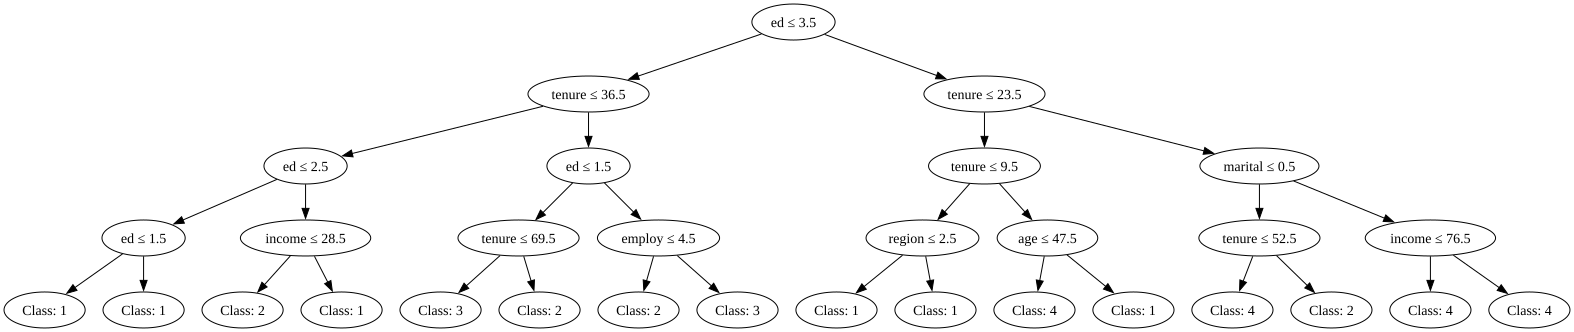

In [14]:
feature_names = df.drop("custcat", axis=1).columns.tolist()

dot = draw_tree_graphviz(model.root, feature_names=feature_names, max_depth=4)
#dot.render("my_tree", format="png", cleanup=True)
display(dot)

# EKSTRA

In [ ]:
decisiontree = DecisionTreeClassifier(max_depth=4, random_state=0)
model = decisiontree.fit(X_train, y_train)

y_pred=model.predict(X_test)

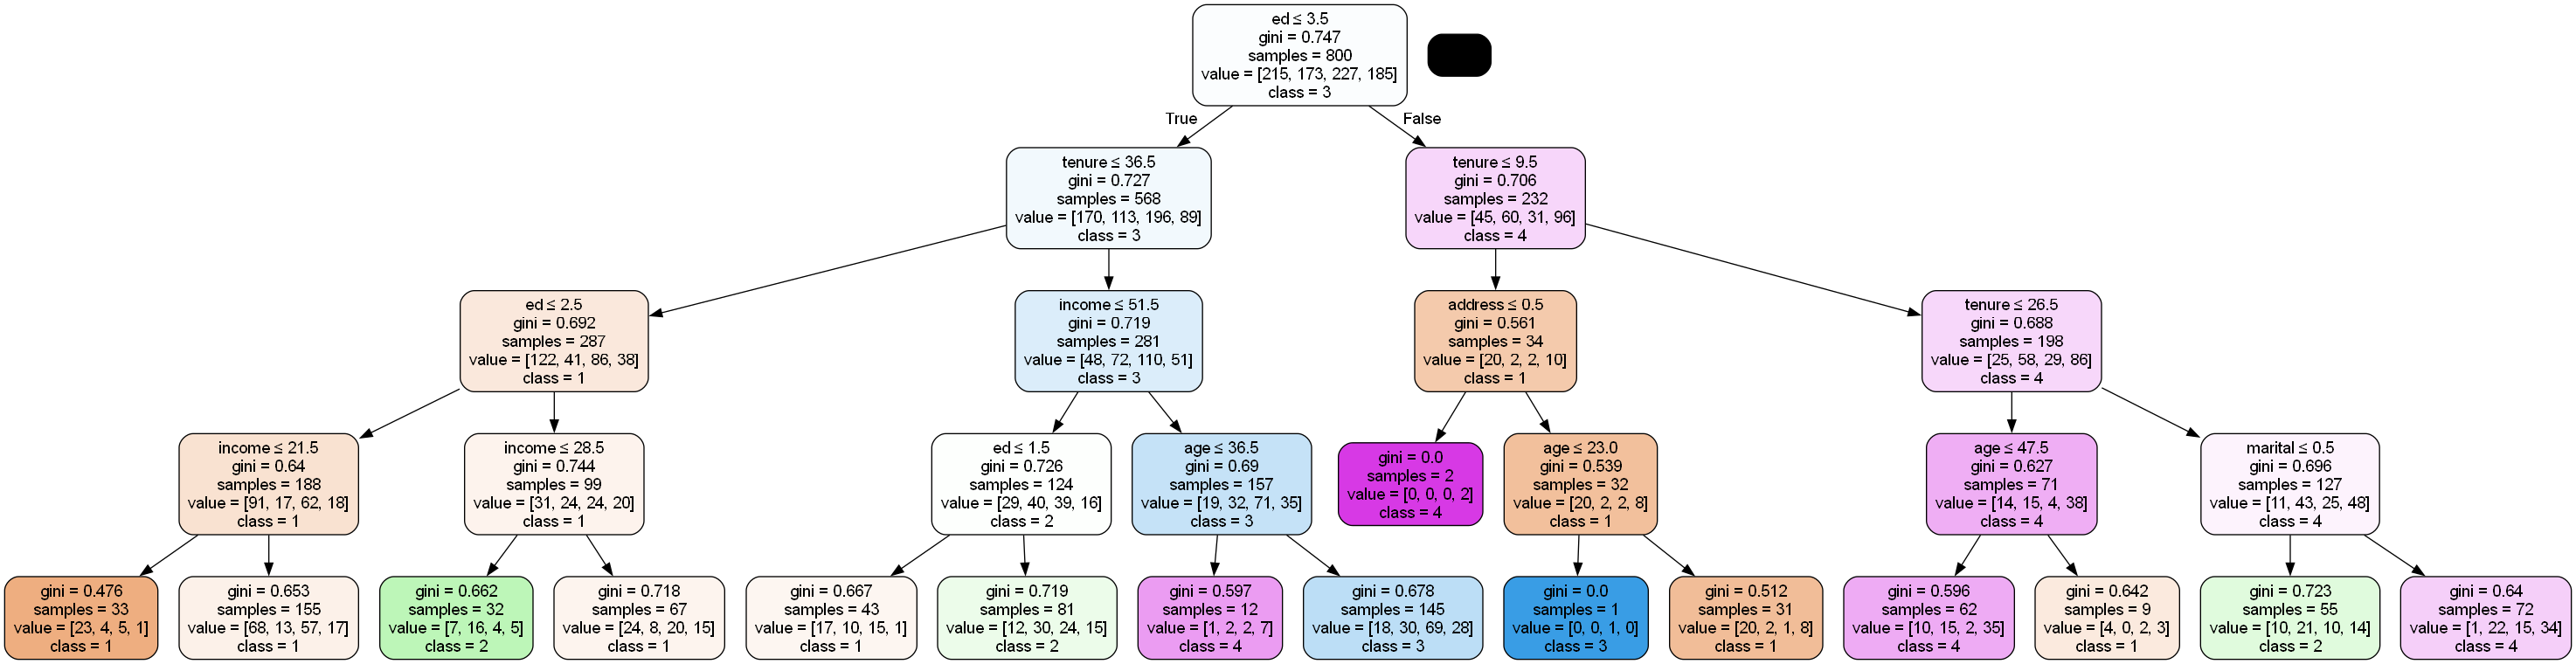

In [19]:
from sklearn.tree import export_graphviz
import pydotplus
from IPython.display import Image

dot_data = export_graphviz(model,
                           out_file=None,
                           feature_names=df.drop("custcat", axis=1).columns,
                           class_names=[str(c) for c in np.unique(y)],
                           filled=True,
                           rounded=True,
                           special_characters=True)

graph = pydotplus.graph_from_dot_data(dot_data)
Image(graph.create_png())